In [1]:
import pickle

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from quartz.data import Grid, pki_grid_scale
from quartz.dataprocessing import (
    kmeans_clustering,
    grid_stddev,
    pair_overlap,
    calculate_pki_avg
)
from quartz.grids import to_dxgrid

def pair_overlap_arrays(
    reference, targets
):
    scores = []
    ref_grid = reference.astype(np.float64)

    for t in targets:
        np_grid = t.astype(np.float64)

        total_diff = np.sum(np.abs(np_grid - ref_grid))
        total_sum = np.sum(np.abs(np_grid)) + np.sum(np.abs(ref_grid))

        if total_sum == 0 or np.isinf(total_sum):
            scores.append(np.nan)
        else:
            scores.append(np.round(1 - (total_diff / total_sum), 4))

    return scores

# KMeans

In [4]:
pki_scaled_grids = [pki_grid_scale(grid) for grid in grids]

In [5]:
grids: list[Grid] = pickle.load(open("grids.pkl", "rb"))
km_clusters = kmeans_clustering([x for x in pki_scaled_grids if x is not None], props=["RESP"], n_clusters=5)

In [9]:
# print("Calculating pKi average")
pki_avg = calculate_pki_avg(grids, props=["RESP"])
# print("Calculating standard deviation")
stdev = grid_stddev(grids, props=["RESP"], means=pki_avg).npGrid["RESP"]

overlap_per_cluster: dict[str, list[float]] = {}
labels_flat = km_clusters.npGrid["RESP"]
for i in range(0, np.max(km_clusters.npGrid["RESP"]) + 1):
    # print(f"Processing cluster {i}")
    indices = labels_flat == i
    masked_grids = [g.npGrid["RESP"][indices] * g.mol_data.pki for g in grids]
    # print(masked_grids[0].shape)


    masked_std = stdev[indices]
    
    # Save masked stdev to dx
    masked_std_grid = np.zeros_like(stdev)
    masked_std_grid[indices] = masked_std
    # print(masked_std_grid.shape)
    to_dxgrid(masked_std_grid, filename="std_cluster_" + str(i) + ".dx", origin=grids[0].grid_props["origin"], spacing=grids[0].grid_props["size"])
    
    if not masked_grids:
        continue

    # print("Calculating mean grid")
    mean_grid = np.mean(masked_grids, axis=0)
    # print("Calculating overlap btwn arrays")
    overlaps = pair_overlap_arrays(masked_std, masked_grids)
    overlap_per_cluster[str(i)] = overlaps

/home/friedrich/Documents/Major/quartz/.pixi/envs/default/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning:

Degrees of freedom <= 0 for slice.



Writing grids/data_std_cluster_0.dx...
Writing grids/data_std_cluster_1.dx...
Writing grids/data_std_cluster_2.dx...
Writing grids/data_std_cluster_3.dx...
Writing grids/data_std_cluster_4.dx...


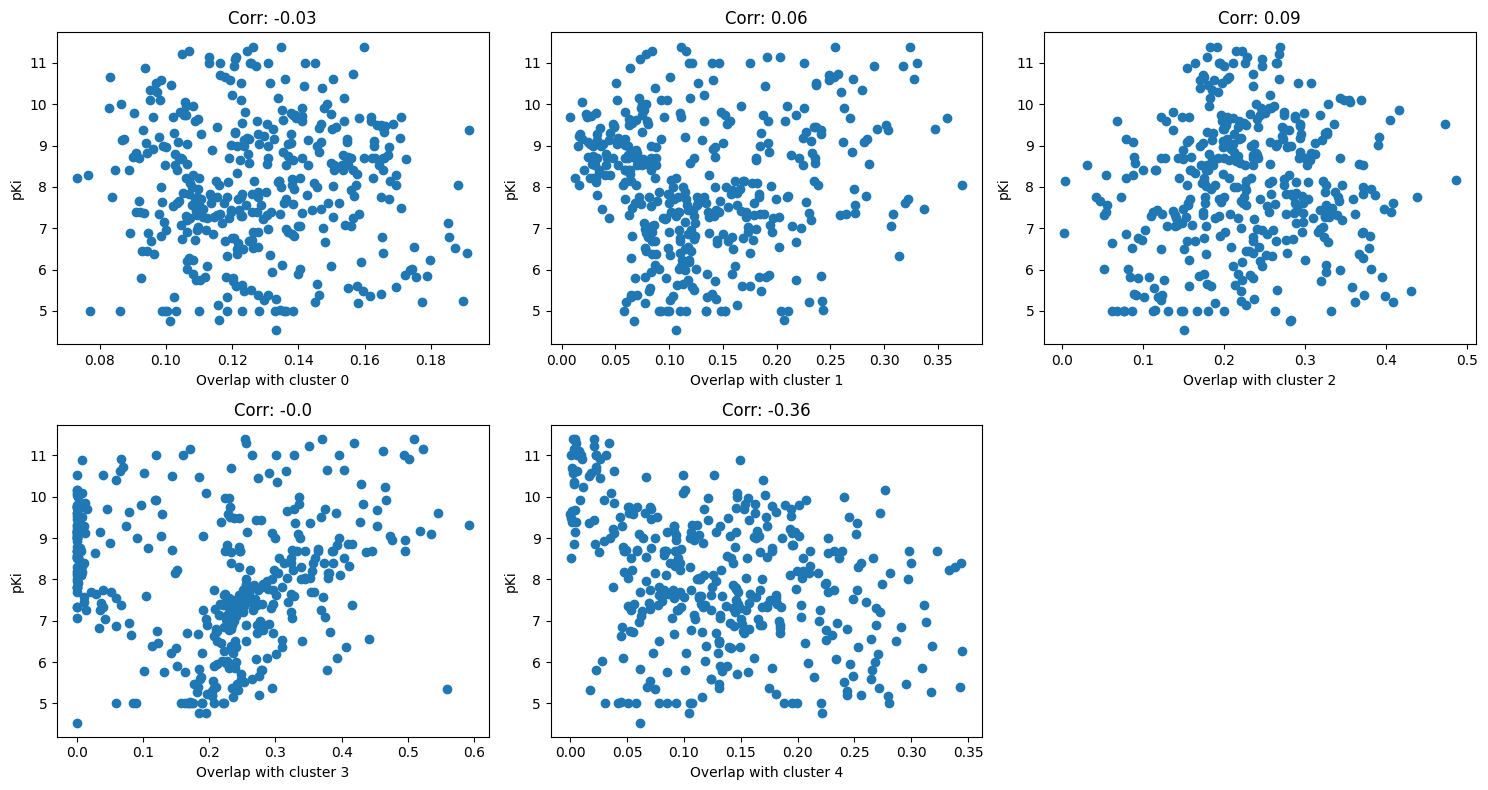

In [11]:
df = pd.DataFrame(overlap_per_cluster)
df["pKi"] = [g.mol_data.pki for g in grids]
df["code"] = [g.mol_data.pdb_code for g in grids]
df.dropna(inplace=True)

cluster_cols = [col for col in df.columns if col != "pKi" and col != "code"]
n_clusters = len(cluster_cols)

n_cols = min(3, n_clusters)  # Max 3 columns
n_rows = (n_clusters + n_cols - 1) // n_cols  # Ceiling division

fig, axs = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))

if n_clusters == 1:
    axs = [axs]
else:
    axs = axs.flatten() if n_clusters > 1 else [axs]

# Plot each cluster
for idx, cluster in enumerate(cluster_cols):
    axs[idx].scatter(df[cluster], df["pKi"])
    axs[idx].set_xlabel(f"Overlap with cluster {cluster}")
    axs[idx].set_ylabel("pKi")
    axs[idx].set_title(f"Corr: {df[cluster].corr(df['pKi']).round(2)}")

# Hide any unused subplots
for idx in range(n_clusters, len(axs)):
    axs[idx].set_visible(False)

plt.tight_layout()
plt.show()


In [8]:
# Control which clusters to plot (exclude cluster 0 by default)
clusters_to_plot = [
    1,
    2,
    3,
    4,
    5,
]  # Modify this list to control which clusters are displayed

# Get cluster labels (3D grid shape)
labels = km_clusters.npGrid["RESP"]

# Generate grid coordinates based on the shape of the cluster data
shape = labels.shape
x_coords, y_coords, z_coords = np.meshgrid(
    np.arange(shape[0]), np.arange(shape[1]), np.arange(shape[2]), indexing="ij"
)

# Flatten all arrays for plotting
x_flat = x_coords.flatten()
y_flat = y_coords.flatten()
z_flat = z_coords.flatten()
labels_flat = labels.flatten()

# Filter to only include selected clusters
mask = np.isin(labels_flat, clusters_to_plot)
x_filtered = x_flat[mask]
y_filtered = y_flat[mask]
z_filtered = z_flat[mask]
labels_filtered = labels_flat[mask]

# Create a plotly 3D scatter plot with discrete colors for clusters
fig = px.scatter_3d(
    x=x_filtered,
    y=y_filtered,
    z=z_filtered,
    color=labels_filtered.astype(str),  # Convert to string for discrete colors
    title="K-Means Clustering of Grid Points",
    labels={"x": "X", "y": "Y", "z": "Z", "color": "Cluster"},
    opacity=0.6,
)
fig.update_traces(marker=dict(size=2))
fig.update_layout(legend_title_text="Cluster")
fig.show()

# Linear regression

In [ ]:
for i in range(0, np.max(km_clusters.npGrid["RESP"]) + 1):
    plt.hist(df.iloc[:, i])
    plt.show()

Mean squared error: 7.64
Coefficient of determination: -1.50


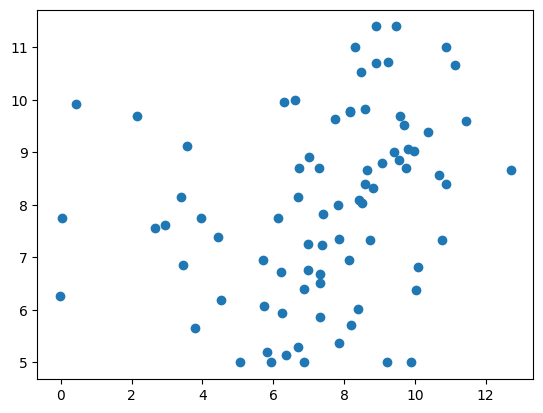

In [12]:
from sklearn import linear_model
from sklearn import gaussian_process
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR

from sklearn.preprocessing import PowerTransformer



X = np.abs(df[cluster_cols].values + 1e-8)
bc = PowerTransformer(method='box-cox')
X_bc = bc.fit_transform(X)

y = df["pKi"].values
X_train, X_test, y_train, y_test = train_test_split(X_bc, y, test_size=0.2, random_state=2137)
# reg = linear_model.LinearRegression().fit(X_train, y_train)
reg = gaussian_process.GaussianProcessRegressor().fit(X_train, y_train)
y_pred = reg.predict(X_test)
print(f"Mean squared error: {mean_squared_error(y_test, y_pred):.2f}")
print(f"Coefficient of determination: {r2_score(y_test, y_pred):.2f}")
plt.scatter(y_pred, y_test)


Cluster 0 Support Vector Regression Results:
Mean squared error: 2.96
Coefficient of determination: -0.02


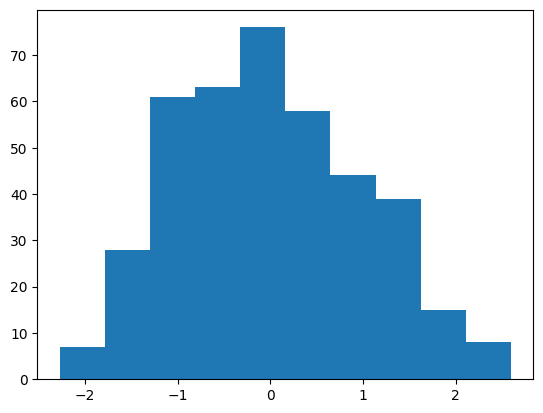

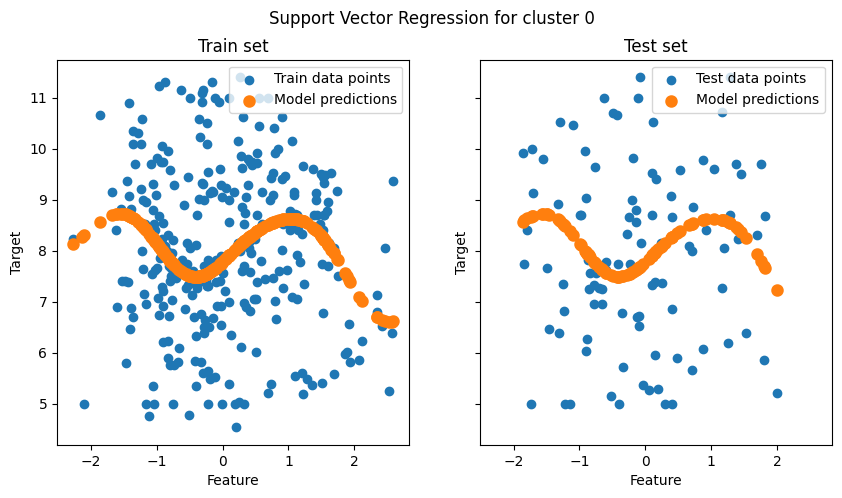

Cluster 1 Support Vector Regression Results:
Mean squared error: 2.37
Coefficient of determination: 0.18


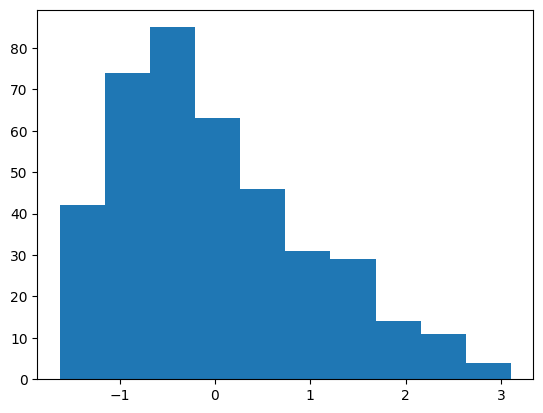

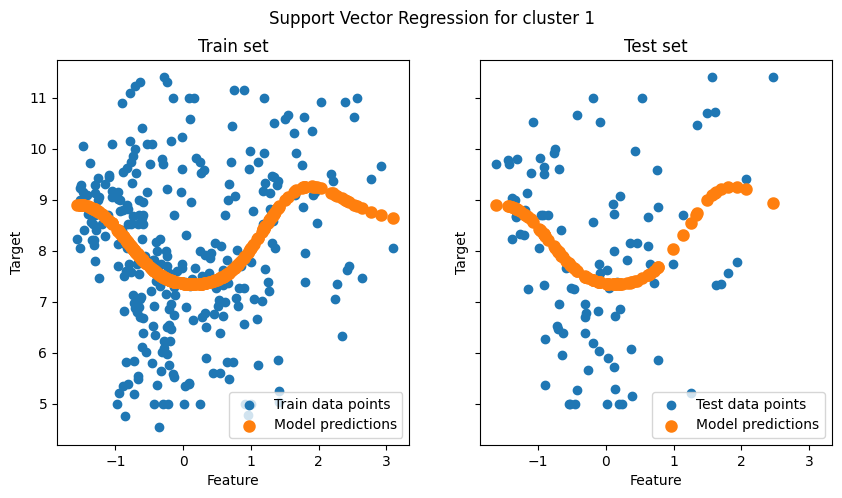

Cluster 2 Support Vector Regression Results:
Mean squared error: 2.77
Coefficient of determination: 0.04


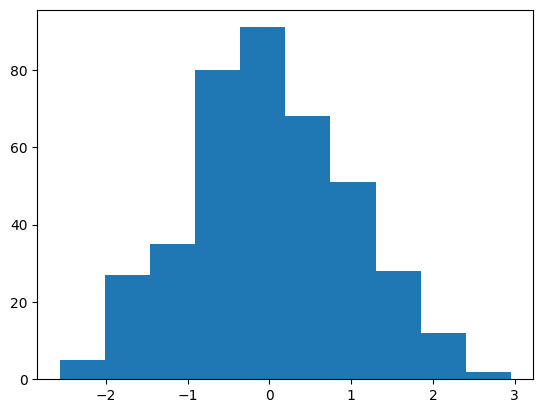

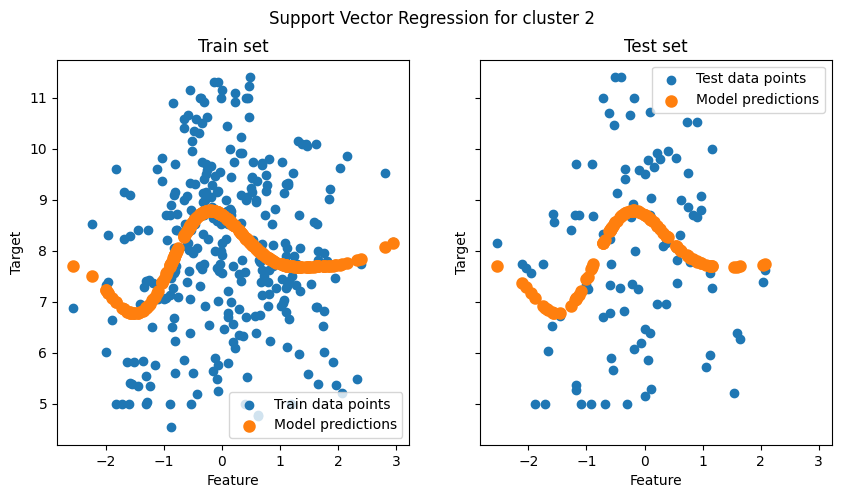

Cluster 3 Support Vector Regression Results:
Mean squared error: 2.08
Coefficient of determination: 0.28


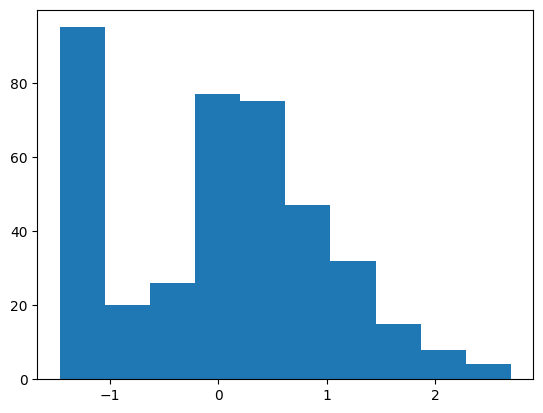

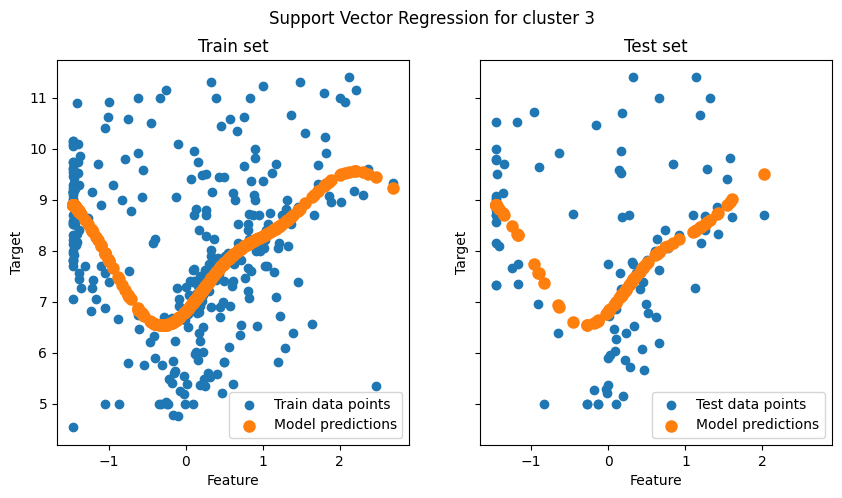

Cluster 4 Support Vector Regression Results:
Mean squared error: 2.46
Coefficient of determination: 0.15


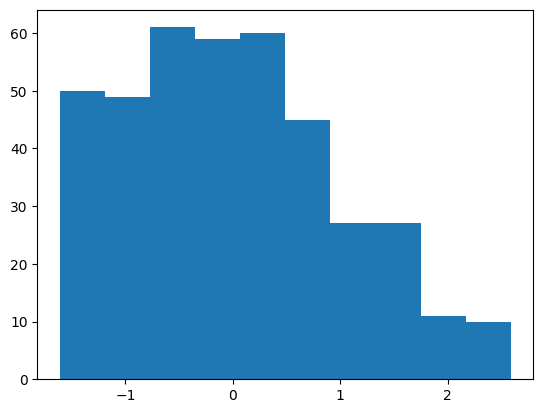

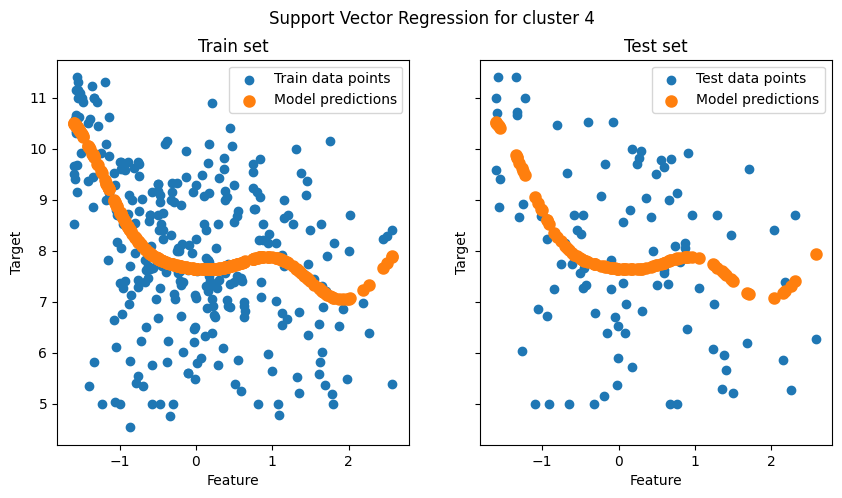

In [13]:
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

for i in range(0, np.max(km_clusters.npGrid["RESP"]) + 1):
    print(f"Cluster {i} Support Vector Regression Results:")

    X = pd.DataFrame(preprocessing.StandardScaler().fit_transform(df.iloc[:, i:i+1]))
    plt.hist(X)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2137)

    reg = SVR(kernel='rbf').fit(X_train, y_train)  # noqa: F821
    y_pred = reg.predict(X_test)

    print(f"Mean squared error: {mean_squared_error(y_test, y_pred):.2f}")
    print(f"Coefficient of determination: {r2_score(y_test, y_pred):.2f}")

    fig, ax = plt.subplots(ncols=2, figsize=(10, 5), sharex=True, sharey=True)
    ax[0].scatter(X_train.iloc[:, 0], y_train, label="Train data points")
    ax[0].scatter(
        X_train.iloc[:, 0],
        reg.predict(X_train),
        linewidth=3,
        color="tab:orange",
        label="Model predictions",
    )
    ax[0].set(xlabel="Feature", ylabel="Target", title="Train set")
    ax[0].legend()

    ax[1].scatter(X_test.iloc[:, 0], y_test, label="Test data points")
    ax[1].scatter(X_test.iloc[:, 0], y_pred, linewidth=3, color="tab:orange", label="Model predictions")
    ax[1].set(xlabel="Feature", ylabel="Target", title="Test set")
    ax[1].legend()

    fig.suptitle(f"Support Vector Regression for cluster {i}")

    plt.show()

In [107]:
test_3d_arr = np.round(np.random.randint(0, 20, size=(10, 5, 5, 5)))
n_mask = np.where(np.count_nonzero(test_3d_arr, axis=0) >= 10, True, False)

# Create output array with same values
out_arr = test_3d_arr.copy()

# Set non-masked voxels to zero across all grids
out_arr[:, ~n_mask] = 0

print(f"Original shape: {test_3d_arr.shape}")
print(f"Output shape: {out_arr.shape}")
print(f"Number of masked voxels: {np.sum(n_mask)}")
print(f"Number of non-zero elements in output: {np.count_nonzero(out_arr)}")
print(f"\nExample slice [0, :, :, 0]:")
print(f"Original:\n{test_3d_arr[0, :, :, 0]}")
print(f"Masked:\n{out_arr[0, :, :, 0]}")

Original shape: (10, 5, 5, 5)
Output shape: (10, 5, 5, 5)
Number of masked voxels: 74
Number of non-zero elements in output: 740

Example slice [0, :, :, 0]:
Original:
[[12  1 10  7 17]
 [ 4  9 17 13  1]
 [12  5 10  4 17]
 [12 14 18  5  0]
 [ 8  2  1  8  6]]
Masked:
[[12  1 10  0  0]
 [ 4  9  0 13  1]
 [ 0  0 10  4 17]
 [12 14  0  0  0]
 [ 8  2  0  8  0]]
